# Assignment 2 – Prediction model of the mobile robot

**Mobile Robotics, KU Leuven** · Team:


Cogilniceanu David, Toghrul Alibayov

**Goal.** The prediction step $\bar{\mathbf x} = \mathbf{Fx} + \mathbf{Bu}$, $\bar{\mathbf P} = \mathbf{FPF}^\mathsf T + \mathbf Q$ for (1) wheel odometry in 1D and (2) IMU dead reckoning in 2D + orientation, with $\mathbf Q$ estimated from measured data, and a comparison of both.

**Logs** (QRoboticsCenter, 10 ms; columns: voltage A/B, wheel speed A/B, wheel angle A/B, accel x/y/z, gyro x/y/z; test sequence in the appendix):

| Log | Experiment | Used for |
|---|---|---|
| R1 | robot still, 80 s | IMU bias and noise, $\mathbf Q$ of scenario 2 |
| R2 / R3 | front / left side lifted | IMU orientation|
| R4 | 30 s still, 2 s at 6 V | wheel-speed noise, both dead-reckoning runs |
| R5 | rotation in place (CW): 5 s still, 8 s at ±4 V, 8 s at ±8 V | lever arm, gyro tilt |

**Ground truth R4** (tape measure): end position 700 mm forward, 190 mm right. The chord points $\arctan(190/700)=15.2°$ to the right; for a path of roughly constant curvature that is half the heading change, so the final heading is $\approx-30°$ and the path length is the arc length $s = c\,\frac{\Delta\theta/2}{\sin(\Delta\theta/2)}$. (The heading noted during the test, 15°, was wrong.)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import Ellipse

def predict(x, P, F, Q, u=None, B=None):
    # Kalman prediction step (same call signature as filterpy.kalman.predict):
    # x_bar = F x + B u,  P_bar = F P F^T + Q
    x = F @ x
    if B is not None and u is not None:
        x = x + B @ u
    return x, F @ P @ F.T + Q

plt.rcParams['figure.figsize'] = (11, 4)
plt.rcParams['axes.grid'] = True

# Robot constants (mecotron.h)
R_WHEEL     = 0.0325   # wheel radius [m]
WHEELBASE   = 0.166    # distance between the wheels [m]
ENCODER_CPR = 1792     # encoder counts per wheel revolution
DT          = 0.01     # sample time [s]
G           = 9.81     # gravity [m/s^2]

COLUMNS = ['VA', 'VB', 'wA', 'wB', 'pA', 'pB', 'ax', 'ay', 'az', 'gx', 'gy', 'gz']

DATA = Path(r'C:\Users\User\Desktop\Mobile Robotics Assignment 2')   # folder with the R1-R5 csv logs

def load_log(filename):
    # Read a QRoboticsCenter log; t = time since start of the log [s]
    df = pd.read_csv(DATA / filename, header=1)
    df.columns = ['Time'] + COLUMNS
    df['t'] = (df['Time'] - df['Time'].iloc[0]) / 1000.0
    return df

def window(df, t_start, t_end):
    return df[(df.t >= t_start) & (df.t < t_end)]

R1 = load_log('R1_static.csv')
R2 = load_log('R2_front_up.csv')
R3 = load_log('R3_left_up.csv')
R4 = load_log('R4_straight_fwd700mm_right190mm_turnR15deg.csv')
R5 = load_log('R5_rotation_CW.csv')

# Ground truth of R4
TRUE_X, TRUE_Y = 0.700, -0.190                          # forward, left [m]
chord = np.hypot(TRUE_X, TRUE_Y)
TRUE_HEADING = 2 * np.arctan2(TRUE_Y, TRUE_X)          # constant-curvature assumption
TRUE_DIST = chord * (TRUE_HEADING / 2) / np.sin(TRUE_HEADING / 2)

T0 = 30.0                                              # dead reckoning starts after the static window
T_MOVE = R4[R4.VA != 0].t.iloc[0]
T_STOP = R4[(R4.t > T_MOVE) & ((R4.wA != 0) | (R4.wB != 0))].t.iloc[-1]

for name, df in [('R1', R1), ('R2', R2), ('R3', R3), ('R4', R4), ('R5', R5)]:
    print(f'{name}: {len(df):5d} samples, {df.t.iloc[-1]:5.1f} s, mean dt {df.Time.diff().mean():.1f} ms')
print(f'R4: moves from {T_MOVE:.2f} s to {T_STOP:.2f} s; final heading {np.degrees(TRUE_HEADING):.1f} deg, '
      f'path length {TRUE_DIST*1000:.0f} mm')

R1:  8073 samples,  80.7 s, mean dt 10.0 ms
R2:  1572 samples,  15.7 s, mean dt 10.0 ms
R3:  1663 samples,  16.6 s, mean dt 10.0 ms
R4:  5334 samples,  53.3 s, mean dt 10.0 ms
R5:  2556 samples,  25.6 s, mean dt 10.0 ms
R4: moves from 31.62 s to 33.77 s; final heading -30.4 deg, path length 734 mm


---
## 1. Scenario 1 – wheel odometry, 1D

The encoders measure the wheel speed, so it is used as **input** (a state $[p, v]$ would need a motor model to predict $v$):

$$x = p,\qquad u = v = R\,\tfrac{\omega_A + \omega_B}{2},\qquad \bar p_k = \underbrace{1}_{\mathbf F}\,p_{k-1} + \underbrace{\Delta t}_{\mathbf B}\,v_k,\qquad \mathbf Q = \mathbf B\,\sigma_v^2\,\mathbf B^\mathsf T$$

In Gaussian terms: the belief $\mathcal N(p, P)$ is shifted by $\mathbf Bu$ and widened by $\mathbf Q$. $\sigma_v$ is the spread of the wheel speed at a **constant voltage** (steady parts of the 6 V drive in R4, excluding the slip at 32.5–32.9 s, each window minus its own mean).

In [2]:
def pooled_std(df, column, windows):
    # Standard deviation around the mean of each window, pooled over the windows
    deviations = [window(df, a, b)[column] - window(df, a, b)[column].mean() for a, b in windows]
    return np.concatenate(deviations).std()

STEADY = [(31.9, 32.45), (33.0, 33.6)]                 # constant 6 V, rolling straight
sigma_wA = pooled_std(R4, 'wA', STEADY)
sigma_wB = pooled_std(R4, 'wB', STEADY)
sigma_v = R_WHEEL * np.sqrt(sigma_wA**2 + sigma_wB**2) / 2

F1 = np.array([[1.0]])
B1 = np.array([[DT]])
Q1 = B1 @ np.array([[sigma_v**2]]) @ B1.T

dt_log = R4.Time.diff().fillna(0).values / 1000
print(f'sigma_wA = {sigma_wA:.3f}, sigma_wB = {sigma_wB:.3f} rad/s -> sigma_v = {sigma_v*1000:.2f} mm/s, Q1 = {Q1[0,0]:.2e} m^2 per step')
print(f'quantisation step 2*pi/(CPR*dt) = {2*np.pi/ENCODER_CPR/DT:.3f} rad/s; check sum(w*dt) vs encoder angle: '
      f'{np.sum(R4.wA*dt_log):.3f} vs {R4.pA.iloc[-1]-R4.pA.iloc[0]:.3f} rad')

sigma_wA = 0.237, sigma_wB = 0.276 rad/s -> sigma_v = 5.90 mm/s, Q1 = 3.49e-09 m^2 per step
quantisation step 2*pi/(CPR*dt) = 0.351 rad/s; check sum(w*dt) vs encoder angle: 23.508 vs 23.513 rad


The speed noise is mostly encoder quantisation. Summing the quantised speeds returns the exact encoder angle (above), so this $\mathbf Q$ is **conservative**: the real long-term errors of wheel odometry are systematic (wheel radius, slip). Dead reckoning on R4, prediction only, from a known start ($p_0 = 0$, $P_0 = 0$) at $T_0 = 30$ s:

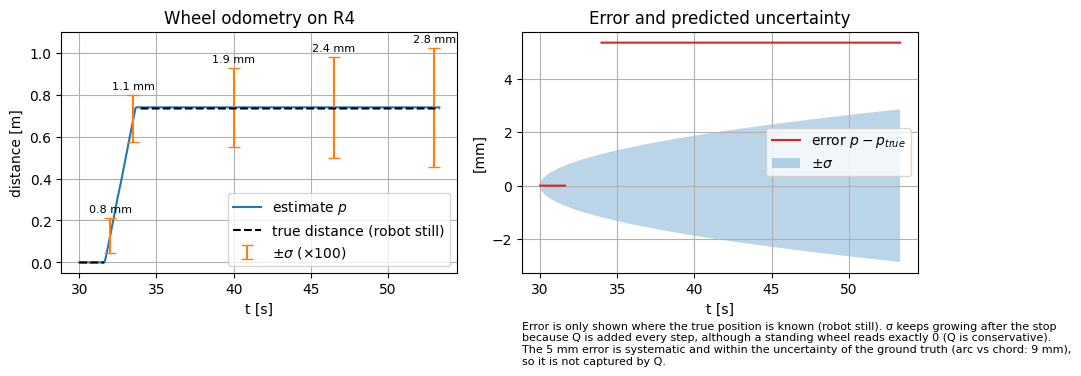

end: p = 739 mm, true = 734 mm, error = +5.3 mm, sigma = 2.9 mm after 23.3 s


In [3]:
def run_wheel_odometry(df, t0):
    # 1D prediction-only run; returns time, estimate p and variance P
    d = df[df.t >= t0]
    x, P = np.array([0.0]), np.array([[0.0]])
    p_hist, P_hist = [], []
    for wA, wB in zip(d.wA, d.wB):
        x, P = predict(x, P, F=F1, Q=Q1, u=np.array([R_WHEEL * (wA + wB) / 2]), B=B1)
        p_hist.append(x[0])
        P_hist.append(P[0, 0])
    return d.t.values, np.array(p_hist), np.array(P_hist)

t1, p1, P1 = run_wheel_odometry(R4, T0)
sig1 = np.sqrt(P1)
p_true = np.where(t1 < T_MOVE, 0.0, np.where(t1 > T_STOP + 0.2, TRUE_DIST, np.nan))   # known while still
err1 = p1 - p_true

fig, (a, b) = plt.subplots(1, 2)
a.plot(t1, p1, label='estimate $p$')
kb = np.searchsorted(t1, [32.0, 33.5, 40.0, 46.5, 53.0])        # error bars, sigma magnified x100
a.errorbar(t1[kb], p1[kb], yerr=100 * sig1[kb], fmt='none', ecolor='C1', capsize=4,
           label=r'$\pm\sigma$ ($\times$100)')
for k in kb:
    a.annotate(f'{sig1[k]*1000:.1f} mm', (t1[k], p1[k] + 100 * sig1[k]), textcoords='offset points',
               xytext=(0, 4), ha='center', fontsize=8)
a.plot(t1, p_true, 'k--', label='true distance (robot still)')
a.set(xlabel='t [s]', ylabel='distance [m]', title='Wheel odometry on R4', ylim=(-0.05, 1.1))
a.legend(loc='lower right')
b.plot(t1, err1 * 1000, 'C3', label=r'error $p - p_{true}$')
b.fill_between(t1, -sig1 * 1000, sig1 * 1000, alpha=0.3, label=r'$\pm\sigma$')
b.set(xlabel='t [s]', ylabel='[mm]', title='Error and predicted uncertainty')
b.legend()
b.text(0, -0.2, 'Error is only shown where the true position is known (robot still). σ keeps growing after the stop\n'
       'because Q is added every step, although a standing wheel reads exactly 0 (Q is conservative).\n'
       'The 5 mm error is systematic and within the uncertainty of the ground truth (arc vs chord: 9 mm),\n'
       'so it is not captured by Q.', transform=b.transAxes, va='top', fontsize=8)
plt.tight_layout()
plt.show()
print(f'end: p = {p1[-1]*1000:.0f} mm, true = {TRUE_DIST*1000:.0f} mm, error = {err1[-1]*1000:+.1f} mm, '
      f'sigma = {sig1[-1]*1000:.1f} mm after {t1[-1]-T0:.1f} s')

---
## 2. Scenario 2 – IMU, 2D + orientation

### 2.1 Calibration

MPU-6050, configured in `adafruit_mpu6050_wrapper.h` (called from `mecotron.h`): **±8 g, ±500 °/s, 21 Hz low-pass** (this overrides the Adafruit library default of ±2 g); output in m/s² and rad/s. Robot frame: $x$ forward, $y$ left, $z$ up, origin in the middle of the axle. Wheel **A = left, B = right**: in R4 both run forward, in R5 A forward and B backward gives a clockwise turn.

**Bias and noise (R1).** Expected noise = datasheet density × $\sqrt{\text{noise bandwidth}}$, bandwidth ≈ $\frac{\pi}{2}\cdot 21$ Hz.

In [4]:
IMU = ['ax', 'ay', 'az', 'gx', 'gy', 'gz']
bw = np.pi / 2 * 21
cal = pd.DataFrame(index=IMU)
cal['bias'] = R1[IMU].mean() - np.array([0, 0, G, 0, 0, 0])      # z: reading minus gravity
cal['datasheet bias limit'] = [0.05 * G, 0.05 * G, 0.08 * G] + [np.radians(20)] * 3   # +-50/80 mg, +-20 deg/s
cal['within'] = cal['bias'].abs() <= cal['datasheet bias limit']
cal['noise std'] = R1[IMU].std()
cal['datasheet noise'] = [400e-6 * G * np.sqrt(bw)] * 3 + [np.radians(0.005) * np.sqrt(bw)] * 3
print('R1 static [m/s^2, rad/s]')
print(cal.round(4).to_string())
print(f"|a| = {np.linalg.norm(R1[['ax','ay','az']].mean()):.2f} m/s^2")

R1 static [m/s^2, rad/s]
      bias  datasheet bias limit  within  noise std  datasheet noise
ax  0.0550                0.4905    True     0.0101           0.0225
ay -0.0543                0.4905    True     0.0100           0.0225
az -0.9923                0.7848   False     0.0146           0.0225
gx -0.0420                0.3491    True     0.0005           0.0005
gy -0.0297                0.3491    True     0.0005           0.0005
gz  0.0523                0.3491    True     0.0006           0.0005
|a| = 8.82 m/s^2


Gyro noise matches the datasheet; the accelerometer is about 2× quieter. The x/y and gyro biases are within the limits, but the **z offset (−0.99 m/s²) is outside** the ±0.78 m/s² tolerance; with $|a| = 8.82$ instead of 9.81 this points to a scale error on $z$. It does not affect the planar model, which only uses $a_x$, $a_y$ (bias-corrected per run) and $\omega_z$. Biases drift, so each run is corrected with its **own static window** (R4: 5–29.5 s).

**Orientation and position**, each from its own experiment:
* **Tilt.** Gravity alone cannot separate a 4° tilt from a 0.7 m/s² offset. The gyro can: during the spins in R5, $\omega_x/\omega_z$ is the same at both speeds, so the IMU $z$ axis is tilted w.r.t. the yaw axis.
* **Yaw.** The axis pointing to a lifted side reads $+g\sin(\text{tilt})$, so in R3 the change of $(a_x, a_y)$ points left. Checks: the acceleration impulse at the start of R4 points forward, the one at the stop backward. R2 (front lifted) gave too small a tilt to be distinguished from the floor unevenness and is not used.
* **Lever arm.** At constant yaw rate the IMU at $\mathbf r$ from the rotation centre measures $\mathbf a = -\omega^2\mathbf r$; both spin speeds must give the same $\mathbf r$.

In [5]:
def angle_deg(dx, dy):
    return np.degrees(np.arctan2(dy, dx))

def imu_to_robot(vx, vy, psi):
    # Rotate a vector from IMU axes to robot axes (psi = robot forward direction in IMU axes)
    return vx * np.cos(psi) + vy * np.sin(psi), -vx * np.sin(psi) + vy * np.cos(psi)

rest5 = window(R5, 0, 5)
SPIN = {'slow (4 V)': (7.5, 12.5), 'fast (8 V)': (15.5, 21.5)}

# Tilt: gyro cross-coupling during the spins
for name, (a, b) in SPIN.items():
    w = window(R5, a, b)[['gx', 'gy', 'gz']].mean() - rest5[['gx', 'gy', 'gz']].mean()
    print(f'tilt  {name}: wx/wz = {w.gx/w.gz:.3f}, wy/wz = {w.gy/w.gz:.3f}')
print(f'      -> IMU z tilted {np.degrees(np.arctan(abs(w.gx / w.gz))):.1f} deg')

# Yaw: lifted side (R3) and start/stop impulses (R4)
acc_R4 = window(R4, 5, 29.5)[['ax', 'ay']].mean()
lift = R3[['ax', 'ay']].mean() - R1[['ax', 'ay']].mean()
start = (window(R4, 31.6, 31.9)[['ax', 'ay']] - acc_R4).sum()
stop = (window(R4, 33.6, 33.9)[['ax', 'ay']] - acc_R4).sum()
yaw = {'R3 left lifted': angle_deg(lift.ax, lift.ay) - 90,
       'R4 start':       angle_deg(start.ax, start.ay),
       'R4 stop':        angle_deg(-stop.ax, -stop.ay)}
for name, a in yaw.items():
    print(f'yaw   {name:15s}: robot forward at {a % 360:6.1f} deg in IMU axes')
ang = np.radians(list(yaw.values()))
PSI = np.arctan2(np.mean(np.sin(ang)), np.mean(np.cos(ang)))
print(f'      -> PSI = {np.degrees(PSI) % 360:.1f} deg: IMU x points backward, y right (spread +-4 deg)')

# Lever arm: centripetal acceleration in R5
r_list = []
for name, (a, b) in SPIN.items():
    seg = window(R5, a, b)
    wz = (seg.gz - rest5.gz.mean()).mean()
    r_imu = -(seg[['ax', 'ay']].mean() - rest5[['ax', 'ay']].mean()).values / wz**2
    r_list.append(imu_to_robot(r_imu[0], r_imu[1], PSI))
    print(f'arm   {name}: r = ({r_imu[0]*1000:.0f}, {r_imu[1]*1000:.0f}) mm in IMU axes')
R_ARM = np.mean(r_list, axis=0)
print(f'      -> IMU {-R_ARM[0]*1000:.0f} mm behind and {R_ARM[1]*1000:.0f} mm left of the axle middle')
seg = window(R5, 15.5, 21.5)
print(f'fast spin yaw rate: gyro {(seg.gz - rest5.gz.mean()).mean():.2f} rad/s, '
      f'wheels {(R_WHEEL * (seg.wB - seg.wA) / WHEELBASE).mean():.2f} rad/s (wheels skid)')

tilt  slow (4 V): wx/wz = -0.071, wy/wz = 0.004
tilt  fast (8 V): wx/wz = -0.071, wy/wz = 0.004
      -> IMU z tilted 4.0 deg
yaw   R3 left lifted : robot forward at  184.8 deg in IMU axes
yaw   R4 start       : robot forward at  181.5 deg in IMU axes
yaw   R4 stop        : robot forward at  176.3 deg in IMU axes
      -> PSI = 180.9 deg: IMU x points backward, y right (spread +-4 deg)
arm   slow (4 V): r = (78, -58) mm in IMU axes
arm   fast (8 V): r = (80, -55) mm in IMU axes
      -> IMU 78 mm behind and 58 mm left of the axle middle
fast spin yaw rate: gyro -5.67 rad/s, wheels -6.10 rad/s (wheels skid)


**Correction of every sample** before it enters the model: (1) subtract the bias of the run's static window; (2) rotate $(a_x, a_y)$ to robot axes with $\psi$; (3) remove the lever-arm terms, $\mathbf a_{IMU} = \mathbf a_{centre} + \dot\omega\,\hat z\times\mathbf r - \omega^2\mathbf r$; (4) rotate to the world frame with the heading $\theta$ (integrated gyro).

In [6]:
def imu_body_inputs(df, t_static):
    # Calibrated [a_forward, a_left, omega] at the axle middle, robot axes
    rest = window(df, *t_static)
    w = (df.gz - rest.gz.mean()).values
    a_fwd, a_left = imu_to_robot((df.ax - rest.ax.mean()).values, (df.ay - rest.ay.mean()).values, PSI)
    w_dot = np.gradient(w, df.t.values)
    a_fwd = a_fwd - (-w_dot * R_ARM[1] - w**2 * R_ARM[0])
    a_left = a_left - (w_dot * R_ARM[0] - w**2 * R_ARM[1])
    return np.column_stack([a_fwd, a_left, w])

def to_world(u_body):
    # Rotate body accelerations to the world frame with the heading before each step (theta_0 = 0)
    theta = np.concatenate([[0.0], np.cumsum(u_body[:-1, 2]) * DT])
    c, s = np.cos(theta), np.sin(theta)
    return np.column_stack([c * u_body[:, 0] - s * u_body[:, 1], s * u_body[:, 0] + c * u_body[:, 1], u_body[:, 2]])

keep4 = (R4.t >= T0).values
u_body = imu_body_inputs(R4, (5, 29.5))[keep4]
u_world = to_world(u_body)

### 2.2 Process model

State $\mathbf x = [x,\ v_x,\ y,\ v_y,\ \theta]^\mathsf T$, input $\mathbf u = [a_x^w,\ a_y^w,\ \omega]^\mathsf T$ (calibrated accelerations already rotated to the world frame). $\mathbf F$ and $\mathbf B$ are then constant and the model is linear:

$$
\mathbf F = \begin{bmatrix} 1 & \Delta t & 0 & 0 & 0\\ 0 & 1 & 0 & 0 & 0\\ 0 & 0 & 1 & \Delta t & 0\\ 0&0&0&1&0\\ 0&0&0&0&1\end{bmatrix},\qquad
\mathbf B = \begin{bmatrix} \tfrac12\Delta t^2 & 0 & 0\\ \Delta t & 0 & 0\\ 0 & \tfrac12\Delta t^2 & 0\\ 0 & \Delta t & 0\\ 0 & 0 & \Delta t\end{bmatrix},\qquad
\mathbf Q = \mathbf B\,\boldsymbol\Sigma_u\,\mathbf B^\mathsf T
$$

$\boldsymbol\Sigma_u = \mathrm{diag}(\sigma_a^2, \sigma_a^2, \sigma_\omega^2)$ from R1. Because $\sigma_{a_x}\approx\sigma_{a_y}$ it does not change under the rotation, so $\mathbf Q$ is constant too. (The rotation uses the estimated heading $\hat\theta$; with this linear $\mathbf F$ the heading uncertainty does not reach the position covariance. Section 2.3 adds this coupling.)

A second, **driving** noise is estimated per body axis: forward from the mismatch between the IMU forward acceleration and the wheel acceleration (gradient of the smoothed wheel speed) during the drive, lateral from $a_l - v\,\omega$ (lateral acceleration minus the centripetal term) on the straight, steady parts. These differ, so the driving $\boldsymbol\Sigma_u$ is rotated with the heading: $\mathbf Q_k = \mathbf B\,\mathbf R(\hat\theta_k)\,\mathrm{diag}(\sigma_f^2, \sigma_l^2)\,\mathbf R(\hat\theta_k)^\mathsf T\,\mathbf B^\mathsf T$ (plus $\sigma_\omega^2$), time-varying while $\mathbf B$ stays constant.

In [7]:
F2 = np.array([[1, DT, 0, 0, 0],
               [0, 1,  0, 0, 0],
               [0, 0,  1, DT, 0],
               [0, 0,  0, 1, 0],
               [0, 0,  0, 0, 1]], dtype=float)
h = 0.5 * DT**2
B2 = np.array([[h, 0, 0], [DT, 0, 0], [0, h, 0], [0, DT, 0], [0, 0, DT]])

sigma_a = np.sqrt((R1.ax.var() + R1.ay.var()) / 2)
sigma_w = R1.gz.std()
Q2 = B2 @ np.diag([sigma_a**2, sigma_a**2, sigma_w**2]) @ B2.T

# Driving noise, forward: IMU forward acceleration minus wheel acceleration while the robot drives
v_wheels = (R_WHEEL * (R4.wA + R4.wB) / 2).rolling(5, center=True, min_periods=1).mean().values[keep4]
a_wheels = np.gradient(v_wheels, R4.t.values[keep4])
t_k = R4.t.values[keep4]
drive = (t_k > T_MOVE) & (t_k < T_STOP)
sigma_f_drive = np.std(u_body[drive, 0] - a_wheels[drive])
# Driving noise, lateral: a_left minus centripetal v*omega on the straight, steady parts (no slip)
straight = np.zeros(len(t_k), dtype=bool)
for a, b in STEADY:
    straight |= (t_k >= a) & (t_k < b)
sigma_l_drive = np.std(u_body[straight, 1] - v_wheels[straight] * u_body[straight, 2])

def Q2_drive(theta):
    # Driving Q: body-axis noise rotated to the world frame with the heading estimate
    c, s = np.cos(theta), np.sin(theta)
    rot = np.array([[c, -s], [s, c]])
    sigma_u = np.zeros((3, 3))
    sigma_u[:2, :2] = rot @ np.diag([sigma_f_drive**2, sigma_l_drive**2]) @ rot.T
    sigma_u[2, 2] = sigma_w**2
    return B2 @ sigma_u @ B2.T

print(f'sigma_a = {sigma_a:.4f} m/s^2 (static); driving: forward {sigma_f_drive:.2f}, lateral {sigma_l_drive:.2f} m/s^2; '
      f'sigma_w = {sigma_w:.5f} rad/s')

def run_imu_dead_reckoning(u_all, Q):
    # 2D prediction-only run from a known start (at rest, heading 0); Q is a matrix or a function of the heading
    x, P = np.zeros(5), np.zeros((5, 5))
    xs, Ps = [], []
    for u in u_all:
        Qk = Q(x[4]) if callable(Q) else Q
        x, P = predict(x, P, F=F2, Q=Qk, u=u, B=B2)
        xs.append(x.copy())
        Ps.append(P.copy())
    return np.array(xs), np.array(Ps)

t2 = R4.t.values[keep4]
X2, P2 = run_imu_dead_reckoning(u_world, Q2)
_, P2d = run_imu_dead_reckoning(u_world, Q2_drive)
sig_pos2 = np.sqrt(P2[:, 0, 0] + P2[:, 2, 2])
sig_pos2d = np.sqrt(P2d[:, 0, 0] + P2d[:, 2, 2])

sigma_a = 0.0101 m/s^2 (static); driving: forward 1.11, lateral 0.26 m/s^2; sigma_w = 0.00062 rad/s


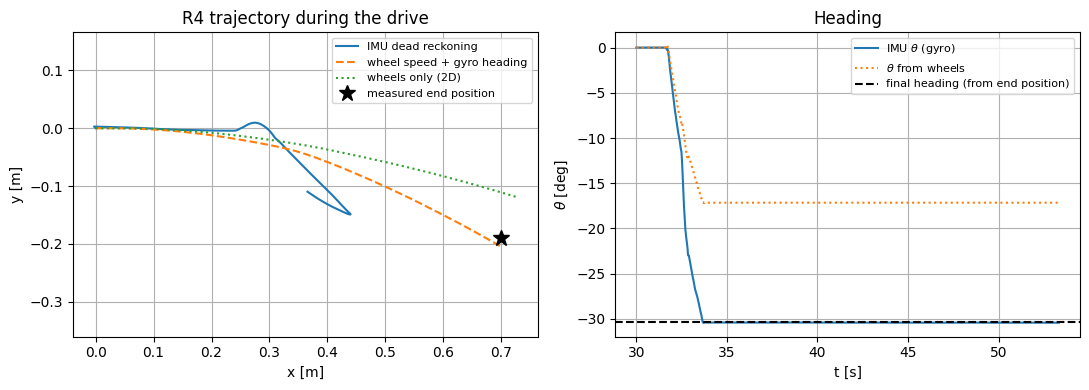

IMU                  at stop: ( 366,  -110) mm, error  344 mm
wheel speed + gyro   at stop: ( 699,  -204) mm, error   14 mm
wheels only 2D       at stop: ( 727,  -119) mm, error   76 mm
final heading: gyro -30.4 deg, wheels -17.1 deg


In [8]:
def dead_reckon_2d(v, w):
    # Reference: integrate speed v with yaw rate w
    x = y = th = 0.0
    out = []
    for vi, wi in zip(v, w):
        x, y, th = x + vi * np.cos(th) * DT, y + vi * np.sin(th) * DT, th + wi * DT
        out.append((x, y, th))
    return np.array(out)

d = R4[keep4]
v_wh = R_WHEEL * (d.wA + d.wB).values / 2
w_wh = R_WHEEL * (d.wB - d.wA).values / WHEELBASE
ref_gyro = dead_reckon_2d(v_wh, u_body[:, 2])
ref_wheel = dead_reckon_2d(v_wh, w_wh)

moving = t2 <= T_STOP + 0.3
fig, (a, b) = plt.subplots(1, 2)
a.plot(X2[moving, 0], X2[moving, 2], label='IMU dead reckoning')
a.plot(ref_gyro[moving, 0], ref_gyro[moving, 1], '--', label='wheel speed + gyro heading')
a.plot(ref_wheel[moving, 0], ref_wheel[moving, 1], ':', label='wheels only (2D)')
a.plot(TRUE_X, TRUE_Y, 'k*', ms=12, label='measured end position')
a.set(xlabel='x [m]', ylabel='y [m]', title='R4 trajectory during the drive')
a.axis('equal')
a.legend(fontsize=8)
b.plot(t2, np.degrees(X2[:, 4]), label=r'IMU $\theta$ (gyro)')
b.plot(t2, np.degrees(ref_wheel[:, 2]), ':', label=r'$\theta$ from wheels')
b.axhline(np.degrees(TRUE_HEADING), color='k', ls='--', label='final heading (from end position)')
b.set(xlabel='t [s]', ylabel=r'$\theta$ [deg]', title='Heading')
b.legend(fontsize=8)
plt.tight_layout()
plt.show()

k = np.searchsorted(t2, T_STOP + 0.3)
for name, xe, ye in [('IMU', X2[k, 0], X2[k, 2]), ('wheel speed + gyro', ref_gyro[k, 0], ref_gyro[k, 1]),
                     ('wheels only 2D', ref_wheel[k, 0], ref_wheel[k, 1])]:
    print(f'{name:20s} at stop: ({xe*1000:4.0f}, {ye*1000:5.0f}) mm, error {np.hypot(xe-TRUE_X, ye-TRUE_Y)*1000:4.0f} mm')
print(f'final heading: gyro {np.degrees(X2[-1,4]):.1f} deg, wheels {np.degrees(ref_wheel[-1,2]):.1f} deg')

**Slip and pitch.** At 32.5–32.9 s the gyro shows a yaw spike the wheels do not see (left): the robot yawed and slid sideways, so wheel-only odometry under-estimates the heading. The IMU distance is too short (right) because the robot pitches while rolling, which leaks part of gravity into the forward acceleration – a bias the static calibration cannot remove.

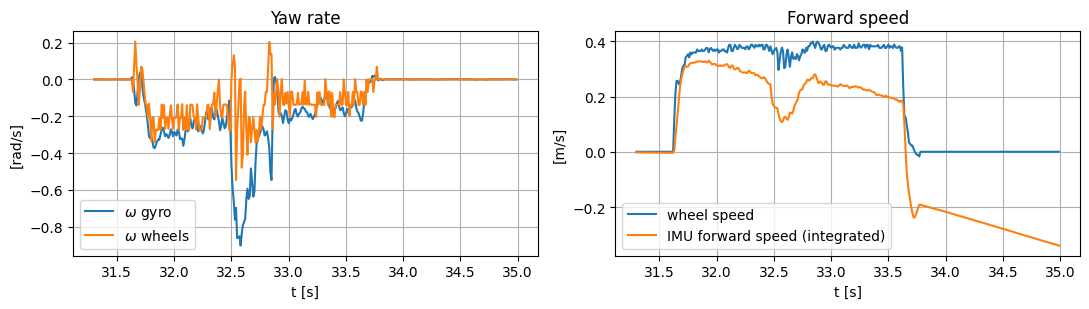

In [9]:
v_fwd_imu = X2[:, 1] * np.cos(X2[:, 4]) + X2[:, 3] * np.sin(X2[:, 4])
seg = (t2 > 31.3) & (t2 < 35)
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.2))
a.plot(t2[seg], u_body[seg, 2], label=r'$\omega$ gyro')
a.plot(t2[seg], w_wh[seg], label=r'$\omega$ wheels')
a.set(xlabel='t [s]', ylabel='[rad/s]', title='Yaw rate')
a.legend()
b.plot(t2[seg], v_wh[seg], label='wheel speed')
b.plot(t2[seg], v_fwd_imu[seg], label='IMU forward speed (integrated)')
b.set(xlabel='t [s]', ylabel='[m/s]', title='Forward speed')
b.legend()
plt.tight_layout()
plt.show()

### 2.3 Heading uncertainty in the position covariance

In 2.2 the accelerations are rotated with the *estimated* heading, $\mathbf a^w = \mathbf R(\hat\theta)\,\mathbf a^b$, and $\mathbf F$ has no entries linking $\theta$ to the position. So $\mathbf P$ never learns that a wrong heading turns the acceleration into the wrong direction. To first order, around the estimate:

$$\mathbf a^w(\theta) \approx \mathbf a^w(\hat\theta) + \frac{\partial \mathbf R}{\partial\theta}\mathbf a^b\,\delta\theta = \mathbf a^w(\hat\theta) + \underbrace{\begin{bmatrix}-a^w_y\\ a^w_x\end{bmatrix}}_{\mathbf J_k}\delta\theta$$

Substituting this into $\bar{\mathbf x} = \mathbf{Fx} + \mathbf{Bu}$ gives a time-varying transition matrix for the **covariance only**. Only the $\theta$ column changes:

$$\mathbf F_k = \mathbf F + \mathbf B_{[:,\,a]}\,\mathbf J_k\,\mathbf e_\theta^\mathsf T \quad\Rightarrow\quad \frac{\partial x}{\partial\theta} = -\tfrac12\Delta t^2 a^w_y,\ \ \frac{\partial v_x}{\partial\theta} = -\Delta t\, a^w_y,\ \ \frac{\partial y}{\partial\theta} = \tfrac12\Delta t^2 a^w_x,\ \ \frac{\partial v_y}{\partial\theta} = \Delta t\, a^w_x$$

$$\bar{\mathbf x} = \mathbf{Fx} + \mathbf{Bu}\ \ (\text{unchanged}),\qquad \bar{\mathbf P} = \mathbf F_k\mathbf P\mathbf F_k^\mathsf T + \mathbf Q_k$$

This is the EKF Jacobian of the nonlinear model. The mean stays the linear prediction of 2.2, and with $P_{\theta\theta}=0$ and $\mathbf J_k=0$ it reduces to the previous result. It creates the cross terms $P_{x\theta}, P_{y\theta}$, through which heading uncertainty grows into position uncertainty **perpendicular to the acceleration**.

**Sources of heading uncertainty.** (1) Gyro white noise, already in $\mathbf Q$ via $\sigma_\omega$. (2) The **mounting yaw** $\psi$ of 2.1: its three estimates spread by a few degrees. An error in $\psi$ rotates every acceleration sample by the same angle, which is the same as an unknown initial heading, so it enters as $P_{0,\theta\theta}=\sigma_\psi^2$.

sigma_psi = 4.3 deg, heading std from gyro noise at the end = 0.017 deg
                                            sigma_pos at stop [mm]  cross-track at stop [mm]  sigma_pos at end [mm]
static Q, no coupling (2.2)                                   6.77                      4.79                  92.62
static Q + heading coupling                                   6.77                      4.79                  92.84
static Q + coupling + sigma_psi = 4.3 deg                    29.31                     28.12                2771.42
driving Q, no coupling (2.2)                                542.44                    276.56                7421.83
driving Q + heading coupling                                542.44                    276.56                7421.83
driving Q + coupling + sigma_psi = 4.3 deg                  543.19                    277.94                7921.85
cross-track std caused by sigma_psi alone at the stop: 28 mm  (check: |IMU displacement| x sigma_psi = 29 mm)


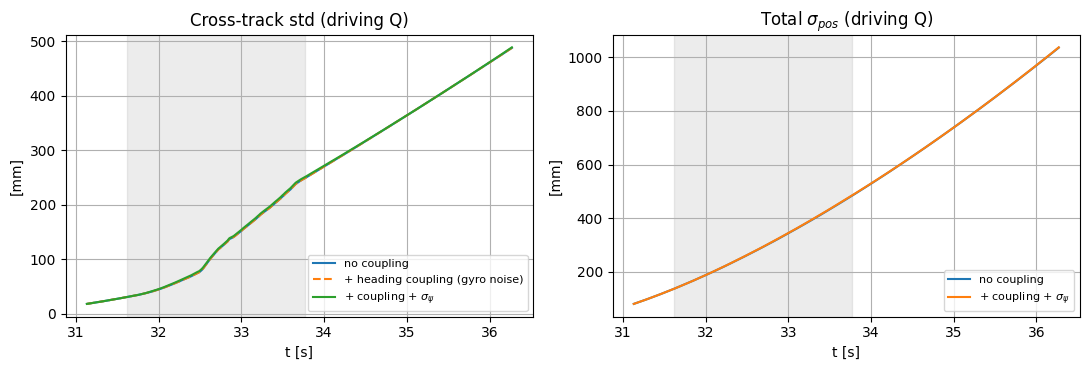

In [10]:
SIGMA_PSI = np.std(np.angle(np.exp(1j * (ang - PSI))), ddof=1)   # spread of the three mounting-yaw estimates, wrapped [rad]

def F_heading(u):
    # Jacobian of the prediction w.r.t. the state, including d(R(theta) a_b)/d(theta) = [-a_y^w, a_x^w]
    Fk = F2.copy()
    Fk[:, 4] += B2[:, :2] @ np.array([-u[1], u[0]])
    return Fk

def run_imu_coupled(u_all, Q, var_theta0=0.0):
    # Same mean as run_imu_dead_reckoning; covariance propagated with the heading Jacobian
    x, P = np.zeros(5), np.zeros((5, 5))
    P[4, 4] = var_theta0
    xs, Ps = [], []
    for u in u_all:
        Qk = Q(x[4]) if callable(Q) else Q
        Fk = F_heading(u)
        x = F2 @ x + B2 @ u
        P = Fk @ P @ Fk.T + Qk
        xs.append(x.copy())
        Ps.append(P.copy())
    return np.array(xs), np.array(Ps)

X2c, P2c = run_imu_coupled(u_world, Q2)                                     # static Q, gyro noise only
_, P2dc = run_imu_coupled(u_world, Q2_drive)                                # driving Q, gyro noise only
_, P2dcp = run_imu_coupled(u_world, Q2_drive, var_theta0=SIGMA_PSI**2)     # driving Q + mounting-yaw uncertainty
_, P2cp = run_imu_coupled(u_world, Q2, var_theta0=SIGMA_PSI**2)            # static Q + mounting-yaw uncertainty
assert np.allclose(X2c, X2), 'the mean must not change'

def sig_xy(P):
    return np.sqrt(P[:, 0, 0] + P[:, 2, 2])

def sig_cross(P, X):
    # std perpendicular to the heading (cross-track)
    n = np.column_stack([-np.sin(X[:, 4]), np.cos(X[:, 4])])
    Pxy = P[:, [0, 2]][:, :, [0, 2]]
    return np.sqrt(np.einsum('ki,kij,kj->k', n, Pxy, n))

k_stop = np.searchsorted(t2, T_STOP + 0.3)
rows = {'static Q, no coupling (2.2)': P2, 'static Q + heading coupling': P2c,
        f'static Q + coupling + sigma_psi = {np.degrees(SIGMA_PSI):.1f} deg': P2cp,
        'driving Q, no coupling (2.2)': P2d, 'driving Q + heading coupling': P2dc,
        f'driving Q + coupling + sigma_psi = {np.degrees(SIGMA_PSI):.1f} deg': P2dcp}
tab = pd.DataFrame({name: [1e3 * sig_xy(P)[k_stop], 1e3 * sig_cross(P, X2)[k_stop], 1e3 * sig_xy(P)[-1]]
                    for name, P in rows.items()},
                   index=['sigma_pos at stop [mm]', 'cross-track at stop [mm]', 'sigma_pos at end [mm]']).T
print(f'sigma_psi = {np.degrees(SIGMA_PSI):.1f} deg, heading std from gyro noise at the end = '
      f'{np.degrees(np.sqrt(P2c[-1, 4, 4])):.3f} deg')
print(tab.round(2).to_string())
s_ind = np.sqrt(sig_cross(P2cp, X2)[k_stop]**2 - sig_cross(P2, X2)[k_stop]**2)
print(f'cross-track std caused by sigma_psi alone at the stop: {1e3*s_ind:.0f} mm  '
      f'(check: |IMU displacement| x sigma_psi = {1e3*np.hypot(X2[k_stop,0], X2[k_stop,2])*SIGMA_PSI:.0f} mm)')

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
seg = (t2 > T_MOVE - 0.5) & (t2 < T_STOP + 2.5)
a.plot(t2[seg], 1e3 * sig_cross(P2d, X2)[seg], label='no coupling')
a.plot(t2[seg], 1e3 * sig_cross(P2dc, X2)[seg], '--', label='+ heading coupling (gyro noise)')
a.plot(t2[seg], 1e3 * sig_cross(P2dcp, X2)[seg], label=r'+ coupling + $\sigma_\psi$')
a.axvspan(T_MOVE, T_STOP, color='grey', alpha=0.15)
a.set(xlabel='t [s]', ylabel='[mm]', title='Cross-track std (driving Q)')
a.legend(fontsize=8)
b.plot(t2[seg], 1e3 * sig_xy(P2d)[seg], label='no coupling')
b.plot(t2[seg], 1e3 * sig_xy(P2dcp)[seg], label=r'+ coupling + $\sigma_\psi$')
b.axvspan(T_MOVE, T_STOP, color='grey', alpha=0.15)
b.set(xlabel='t [s]', ylabel='[mm]', title=r'Total $\sigma_{pos}$ (driving Q)')
b.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Result.** The coupling works as expected: a heading error $\delta\theta$ moves the predicted position by about $|\Delta\mathbf p|\,\delta\theta$ perpendicular to the path, which is the check printed above. For this run it is still a **small** part of the total:

* Gyro white noise gives a heading std of only about 0.02° after 23 s, so the coupling through $\mathbf Q$ alone changes nothing visible.
* The mounting-yaw uncertainty $\sigma_\psi\approx 4°$ adds about 3 cm cross-track at the stop. That is several times the static-$\mathbf Q$ uncertainty, so a filter that uses the static $\mathbf Q$ must include it. With the driving $\mathbf Q$ it disappears in quadrature under the 0.3 m from vibration and pitch.
* It grows with the distance travelled, while the acceleration noise grows with $t^{3/2}$. The coupling matters most for long, fast runs with a small acceleration noise, and for a gyro **bias** (heading error growing $\propto t$), which is the next term to add to the state.

The mean prediction is unchanged, so all trajectories and errors above remain valid. Only $\mathbf P$ changes. The ellipses in section 3 use the driving $\mathbf Q$, where the coupling makes them less than 1 % larger.

---
## 3. Comparison

The true position is only known while the robot stands still (before the start, after the stop). Wheels: 1D error along the path; IMU: 2D position error. Dotted lines: theory.

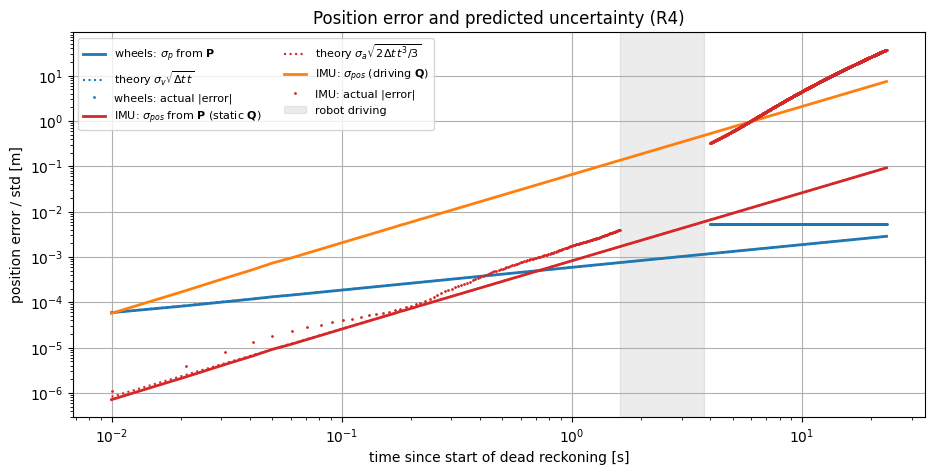

wheels after 23.3 s: error 5.3 mm, sigma 2.9 mm
IMU at stop / end: error 0.34 / 37.5 m; sigma static Q 6.8 mm / 0.09 m; sigma driving Q 0.54 / 7.4 m
residual bias after the stop: 0.18 m/s^2 (= floor tilt 1.1 deg) -> 1/2 b t^2 = 35 m in 20 s


In [11]:
xt = np.where(t2 < T_MOVE, 0.0, np.where(t2 > T_STOP + 0.2, TRUE_X, np.nan))
yt = np.where(t2 < T_MOVE, 0.0, np.where(t2 > T_STOP + 0.2, TRUE_Y, np.nan))
err2 = np.hypot(X2[:, 0] - xt, X2[:, 2] - yt)
tau = t2 - T0 + DT                                   # time since start of dead reckoning

plt.figure(figsize=(11, 5))
plt.loglog(tau, sig1, 'C0', lw=2, label=r'wheels: $\sigma_p$ from $\mathbf{P}$')
plt.loglog(tau, sigma_v * np.sqrt(DT * tau), 'C0:', label=r'theory $\sigma_v\sqrt{\Delta t\,t}$')
plt.loglog(tau, np.abs(err1), 'C0.', ms=2, label='wheels: actual |error|')
plt.loglog(tau, sig_pos2, 'C3', lw=2, label=r'IMU: $\sigma_{pos}$ from $\mathbf{P}$ (static $\mathbf{Q}$)')
plt.loglog(tau, sigma_a * np.sqrt(2 * DT * tau**3 / 3), 'C3:', label=r'theory $\sigma_a\sqrt{2\Delta t\,t^3/3}$')
plt.loglog(tau, sig_pos2d, 'C1', lw=2, label=r'IMU: $\sigma_{pos}$ (driving $\mathbf{Q}$)')
plt.loglog(tau, err2, 'C3.', ms=2, label='IMU: actual |error|')
plt.axvspan(T_MOVE - T0, T_STOP - T0, color='grey', alpha=0.15, label='robot driving')
plt.xlabel('time since start of dead reckoning [s]')
plt.ylabel('position error / std [m]')
plt.title('Position error and predicted uncertainty (R4)')
plt.legend(fontsize=8, ncol=2)
plt.show()

k = np.searchsorted(t2, T_STOP + 0.3)
print(f'wheels after {tau[-1]:.1f} s: error {abs(err1[-1])*1000:.1f} mm, sigma {sig1[-1]*1000:.1f} mm')
print(f'IMU at stop / end: error {err2[k]:.2f} / {err2[-1]:.1f} m; sigma static Q {sig_pos2[k]*1000:.1f} mm / {sig_pos2[-1]:.2f} m; '
      f'sigma driving Q {sig_pos2d[k]:.2f} / {sig_pos2d[-1]:.1f} m')

# Residual bias: calibrated static acceleration after the stop (zero before the drive by construction)
u_all = imu_body_inputs(R4, (5, 29.5))
b_res = np.hypot(*u_all[(R4.t > T_STOP + 1).values, :2].mean(axis=0))
t_after = R4.t.iloc[-1] - T_STOP
print(f'residual bias after the stop: {b_res:.2f} m/s^2 (= floor tilt {np.degrees(np.arcsin(b_res / G)):.1f} deg) '
      f'-> 1/2 b t^2 = {0.5 * b_res * t_after**2:.0f} m in {t_after:.0f} s')

The static $\mathbf Q$ only contains sensor noise at rest; the driving $\sigma_a$ also contains vibration, pitch leakage and slip, which is what actually corrupts the IMU while the robot moves – hence its $\mathbf P$ is much closer to the real error than with the static $\mathbf Q$ (which underestimates it by a factor 50–400).

**Gaussian belief** $\mathcal N(\mathbf x, \mathbf P)$ at three moments: wheels as 1D density (deviation from the mean), IMU as 95 % ellipses of $(x, y)$ along the predicted path (driving $\mathbf Q$; with the static $\mathbf Q$ the ellipses would be invisible at this scale). The driving noise is about 4× larger forward than sideways, so the ellipses are stretched along the direction of travel.

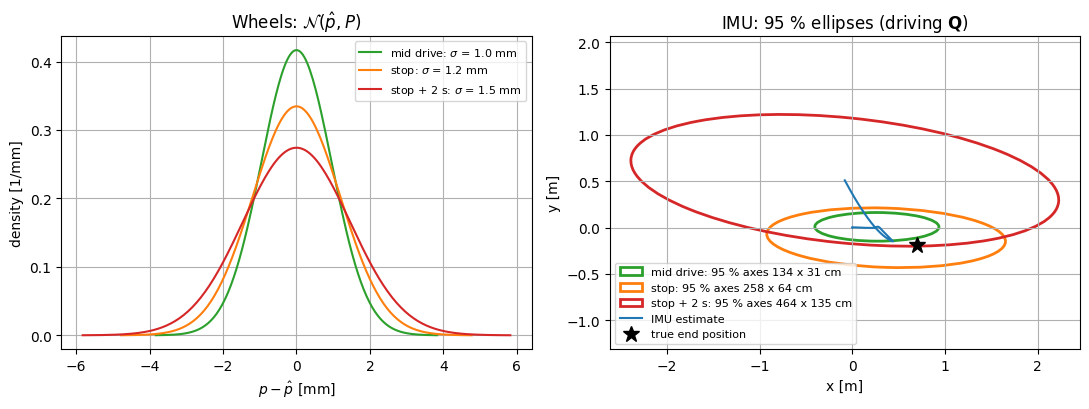

In [12]:
moments = {'mid drive': T_MOVE + 1.0, 'stop': T_STOP + 0.3, 'stop + 2 s': T_STOP + 2.3}
idx = {name: np.searchsorted(t2, tm) for name, tm in moments.items()}
CHI2_95 = 5.991                                       # 95 % for 2 degrees of freedom

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2))
for (name, k), c in zip(idx.items(), ['C2', 'C1', 'C3']):
    s = sig1[k]
    z = np.linspace(-4 * s, 4 * s, 200)
    a.plot(z * 1000, np.exp(-z**2 / (2 * s**2)) / (s * np.sqrt(2 * np.pi)) / 1000, c,
           label=f'{name}: $\\sigma$ = {s*1000:.1f} mm')
    lam, vec = np.linalg.eigh(P2d[k][np.ix_([0, 2], [0, 2])])      # (x, y) block of P
    ax_len = 2 * np.sqrt(CHI2_95 * lam)                              # full axis lengths
    b.add_patch(Ellipse((X2[k, 0], X2[k, 2]), ax_len[1], ax_len[0], angle=angle_deg(vec[0, 1], vec[1, 1]),
                        fill=False, color=c, lw=2,
                        label=f'{name}: 95 % axes {ax_len[1]*100:.0f} x {ax_len[0]*100:.0f} cm'))
a.set(xlabel=r'$p - \hat p$ [mm]', ylabel='density [1/mm]', title='Wheels: $\\mathcal{N}(\\hat p, P)$')
a.legend(fontsize=8)
last = idx['stop + 2 s'] + 1
b.plot(X2[:last, 0], X2[:last, 2], 'C0', label='IMU estimate')
b.plot(TRUE_X, TRUE_Y, 'k*', ms=12, label='true end position')
b.set(xlabel='x [m]', ylabel='y [m]', title='IMU: 95 % ellipses (driving $\\mathbf{Q}$)')
b.axis('equal')
b.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Results

| | State $\mathbf x$ | Input $\mathbf u$ | $\mathbf F$ | $\mathbf B$ | $\mathbf Q$ |
|---|---|---|---|---|---|
| **1. Wheels** | $p$ | $v = R\frac{\omega_A+\omega_B}{2}$ | $[1]$ | $[\Delta t] = [0.01]$ | $\Delta t^2\sigma_v^2$ = 3.5·10⁻⁹ m² per step ($\sigma_v$ = 5.9 mm/s) |
| **2. IMU** | $[x, v_x, y, v_y, \theta]$ | $[a_x^w, a_y^w, \omega]$ | constant velocity, see 2.2 | see 2.2, $\Delta t$ = 0.01 | $\mathbf B\boldsymbol\Sigma_u\mathbf B^\mathsf T$, $\boldsymbol\Sigma_u = \mathrm{diag}(0.0101^2, 0.0101^2, 0.00062^2)$; per axis $\sigma_a^2\begin{bmatrix}\Delta t^4/4 & \Delta t^3/2\\ \Delta t^3/2 & \Delta t^2\end{bmatrix}$ = $\begin{bmatrix}2.5\cdot10^{-13} & 5.1\cdot10^{-11}\\ 5.1\cdot10^{-11} & 1.0\cdot10^{-8}\end{bmatrix}$, $Q_{\theta\theta}$ = 3.8·10⁻¹¹ |
| | | | | | driving: $\sigma_f$ = 1.11, $\sigma_l$ = 0.26 m/s², rotated with $\hat\theta$: $\mathbf Q_k = \mathbf B\mathbf R(\hat\theta_k)\boldsymbol\Sigma_u\mathbf R(\hat\theta_k)^\mathsf T\mathbf B^\mathsf T$ |

| R4 (0.73 m drive) | Wheels (1D) | IMU (2D) |
|---|---|---|
| error after the drive | 5 mm | 0.34 m |
| error after 23 s | 5 mm ($\sigma$ = 2.9 mm) | 37 m ($\sigma$ = 0.09 m static / 7 m driving $\mathbf Q$) |
| heading | – | gyro −30.4° (wheels −17.1°, truth ≈ −30°) |

### Discussion

**Theory.** Wheel odometry integrates the measured speed **once**: $P_k = k\,\Delta t^2\sigma_v^2$, so the variance grows **linearly** ($\sigma\propto\sqrt t$) and a constant speed error (wheel radius) only gives an error $\propto t$. The IMU integrates the acceleration **twice**: $\mathbf{FPF}^\mathsf T$ feeds the velocity variance into the position each step, so $\sigma_p^2\approx\sigma_a^2\,\Delta t\,t^3/3$ (**variance $\propto t^3$**), a bias $b$ drifts as $\tfrac12 b t^2$ (**$\propto t^2$**), and a gyro bias turns the acceleration into the wrong direction. The $\mathbf P$ curves follow these slopes exactly.

**Data.** The IMU error is dominated by bias that a static calibration cannot remove: pitch while driving, and after the stop a residual of 0.18 m/s² (the floor tilts about 1.1° more at the end spot), which integrates to 35 m in 20 s. A real filter has to put the bias in the state and correct it with an update step.

**Heading coupling (2.3).** Linearising $\mathbf R(\theta)\mathbf a^b$ around $\hat\theta$ adds the $\theta$ column $\mathbf B_a[-a^w_y,\ a^w_x]^\mathsf T$ to the covariance transition. Heading uncertainty then grows into cross-track position uncertainty of about $|\Delta\mathbf p|\,\sigma_\theta$. Here the gyro noise is too small to matter, and the ~4° mounting-yaw uncertainty adds about 3 cm at the stop. That is large compared with the static $\mathbf Q$, but small next to the driving noise and the bias drift.

**Slip.** Wheel odometry assumes rolling without slip. In R4 the wheels missed about 13° of yaw and in R5 they over-count the yaw rate by 7 % (skid). The gyro measures the body motion itself and is not affected.

### Conclusion

**Wheel odometry is the more accurate dead-reckoning approach:** it integrates a directly measured speed once, its variance grows linearly and the error stays at the mm level. The IMU integrates twice (variance $\propto t^3$, bias drift $\propto t^2$), so its position is unusable after a few seconds. Its strength is the gyro heading, which captures slip; the best prediction model combines **wheel speed for distance with the gyro for heading** (dashed trajectory above).

---
### Appendix – test sequence in `robot.cpp` (R1–R5)

```cpp
// t = i / 100 s since the button press; outputs out[0..11] = VA, VB, wA, wB, pA, pB, ax, ay, az, gx, gy, gz
// R1-R3: no button, motors off (R2/R3: robot lifted by hand)
if (test == 0) {                                   // Button 0 -> stop
  MV[0] = 0.0; MV[1] = 0.0;
} else if (test == 1) {                            // Button 1 -> R4
  if (t >= 30.0 && t < 32.0) { MV[0] = 6.0; MV[1] = 6.0; }      // 30 s still, 2 s at 6 V
} else if (test == 2) {                            // Button 2 -> R5
  if      (t >= 5.0  && t < 13.0) { MV[0] = 4.0; MV[1] = -4.0; } // 5 s still, 8 s at +-4 V
  else if (t >= 13.0 && t < 21.0) { MV[0] = 8.0; MV[1] = -8.0; } // 8 s at +-8 V
}
```